# Reversible Data Hiding

Zhicheng Ni, Yun-Qing Shi, Nirwan Ansari, and Wei Su; IEEE TRANSACTIONS ON CIRCUITS AND SYSTEMS FOR VIDEO TECHNOLOGY, VOL. 16, NO. 3, MARCH 2006

## Overview

Core idea is based on histogram shifting. Given a grayscale image with 256 levels we can obtain:

- peak point - the level with the most pixels
- minimum point - the level with the fewest pixels (ideally 0)

Pixels belonging to the peak are modified with embedded payload. Embedding capacity is equal to the number of peak occurrences - 1 bit per peak pixel.

The paper describes grayscale images. In this approach we will treat each channel (R, G, B) as a separate 8-bit image.

## Data preparation

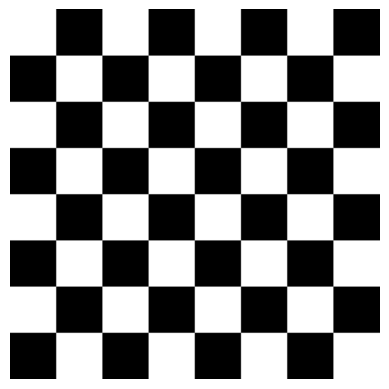

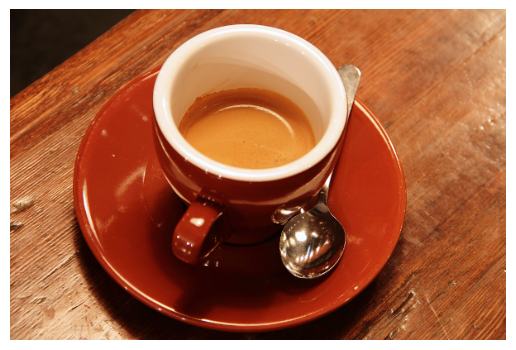

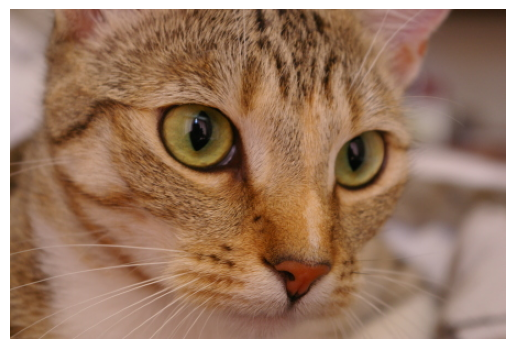

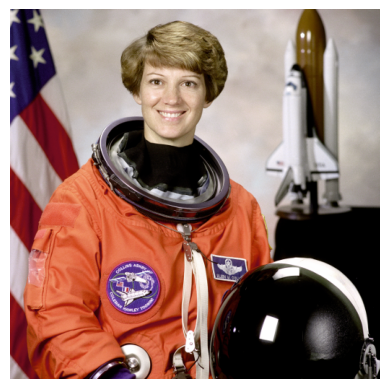

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## Implementation

### Get peak and minimum points

In [2]:
channel_names = ["R", "G", "B"]

def compute_histogram(channel):
    return np.bincount(channel.ravel(), minlength=256)

def find_peak_and_minimum_points(histogram):
    peak_point = int(np.argmax(histogram))
    minimum_point = int(np.argmin(histogram))
    return peak_point, minimum_point

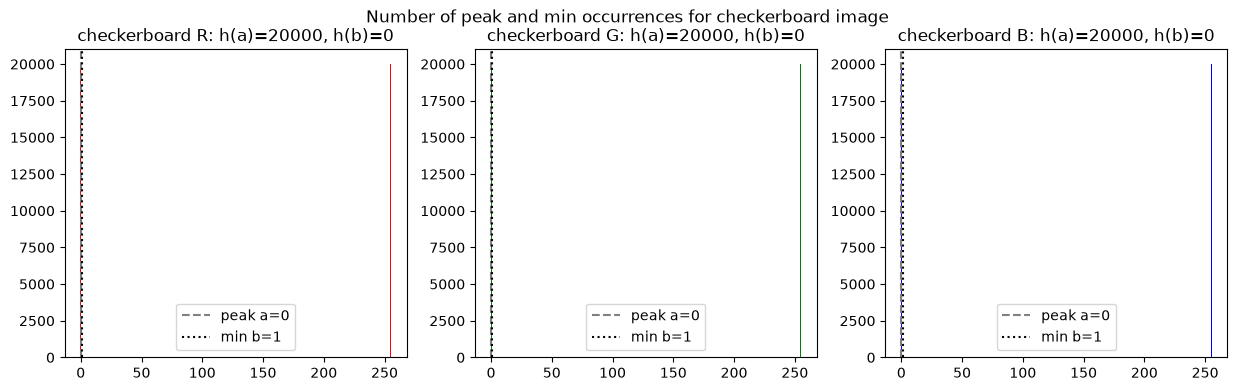

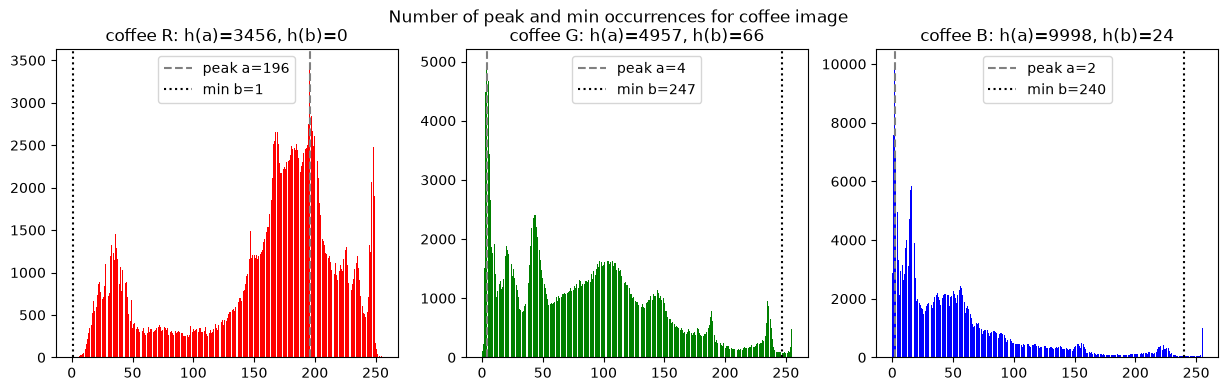

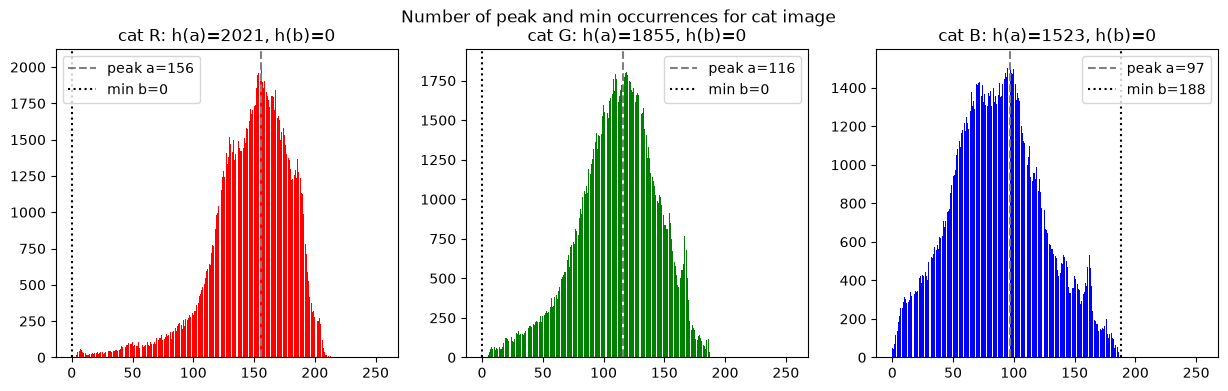

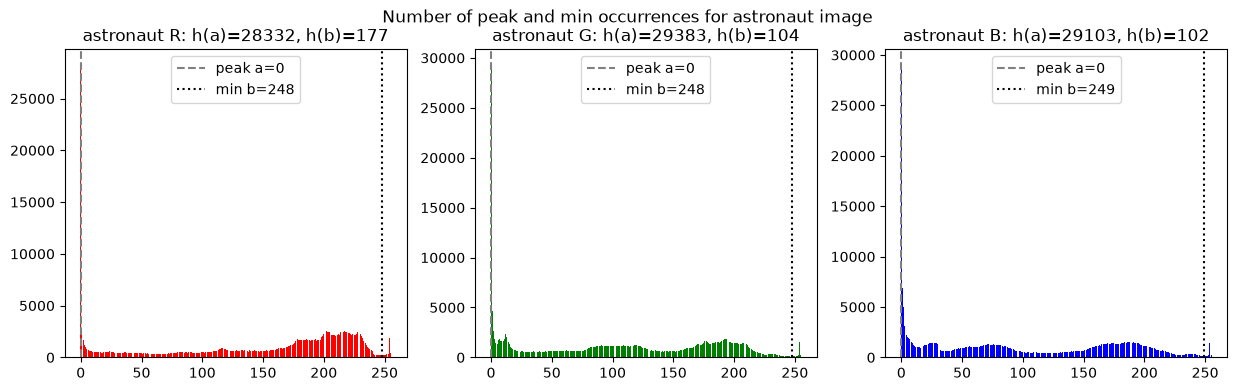

In [3]:
for image_name, image in zip(image_names, imgs_color):
    figure, axes = plt.subplots(1, 3, figsize=(15, 4))
    figure.suptitle(f"Number of peak and min occurrences for {image_name} image")
    for channel_index, axis in enumerate(axes):
        histogram = compute_histogram(image[:, :, channel_index])
        peak_point, minimum_point = find_peak_and_minimum_points(histogram)

        axis.bar(range(256), histogram, color=channel_names[channel_index].lower())
        axis.axvline(peak_point, color="gray", linestyle="--", label=f"peak a={peak_point}")
        axis.axvline(minimum_point, color="black", linestyle=":", label=f"min b={minimum_point}")
        axis.set_title(
            f"{image_name} {channel_names[channel_index]}: "
            f"h(a)={histogram[peak_point]}, h(b)={histogram[minimum_point]}"
        )
        axis.legend()
    plt.show()

### Embedding the information

1. Shift pixels strictly between `a` (peak) and `b` (min) by 1 towards `b`
2. For each pixel equal to `a` (raster order): bit `1` moves it one level towards `b`, bit `0` leaves it
3. Pixels originally equal to `b` are returned as overhead (indices)

The paper assumes `a < b`, for `a > b` everything is mirrored via reversing the shifting direction.

In [4]:
def embed_channel(channel, bits, peak_point, minimum_point):
    direction = 1 if minimum_point > peak_point else -1
    original = channel.ravel().astype(np.int16) # flatten the channel to 1D, int16 so +/-1 shifts can't overflow uint8
    marked = original.copy()

    # shift pixels between minimum and peak
    lower, upper = sorted((peak_point, minimum_point))
    marked[(original > lower) & (original < upper)] += direction

    # get the positions of the peak point in the original image
    peak_positions = np.flatnonzero(original == peak_point)
    if len(bits) > len(peak_positions):
        raise ValueError(f"Payload of {len(bits)} bits exceeds capacity {len(peak_positions)}")

    # embed the bits into the marked image at the peak positions
    marked[peak_positions[:len(bits)]] += direction * np.asarray(bits)

    # get the positions of the minimum point in the original image for overhead
    overhead = np.flatnonzero(original == minimum_point)
    
    return marked.astype(np.uint8).reshape(channel.shape), overhead

### Extraction

1. Scan in the same raster order. A pixel equal to `a + direction` is bit `1`, a pixel equal to `a` is bit `0`
2. Shift pixels in `[b, a)` back by 1 (mirrored for `a > b`)
3. Set the overhead pixels back to `b`

In [5]:
def extract_channel(marked_channel, peak_point, minimum_point, overhead, bit_count):
    direction = 1 if minimum_point > peak_point else -1
    marked = marked_channel.ravel().astype(np.int16) # flatten the channel to 1D, int16 so shifts can't overflow uint8

    # get positions of pixels with embedded information
    is_data_pixel = (marked == peak_point) | (marked == peak_point + direction)
    is_data_pixel[overhead] = False
    data_positions = np.flatnonzero(is_data_pixel)[:bit_count]

    # get bit values from pixels with embedded data
    bits = (marked[data_positions] == peak_point + direction)

    # get positions of shifted pixels
    is_shifted = ((marked - peak_point) * direction > 0) & ((marked - minimum_point) * direction <= 0)
    
    # unshift pixels values
    marked[is_shifted] -= direction

    # restore original values of pixels with min value
    marked[overhead] = minimum_point
    return marked.astype(np.uint8).reshape(marked_channel.shape), bits

### Usage

Random payload is embedded and extracted for values comparison. Distortion is measured in Peak Signal-to-Noise Ratio (PSNR).

checkerboard  R: capacity= 20000, overhead=   0, PSNR=54.12 dB, lossless=True
checkerboard  G: capacity= 20000, overhead=   0, PSNR=54.21 dB, lossless=True
checkerboard  B: capacity= 20000, overhead=   0, PSNR=54.18 dB, lossless=True
coffee        R: capacity=  3456, overhead=   0, PSNR=49.65 dB, lossless=True
coffee        G: capacity=  4957, overhead=  66, PSNR=48.32 dB, lossless=True
coffee        B: capacity=  9998, overhead=  24, PSNR=48.45 dB, lossless=True
cat           R: capacity=  2021, overhead=   0, PSNR=50.67 dB, lossless=True
cat           G: capacity=  1855, overhead=   0, PSNR=50.88 dB, lossless=True
cat           B: capacity=  1523, overhead=   0, PSNR=52.29 dB, lossless=True
astronaut     R: capacity= 28332, overhead= 177, PSNR=48.44 dB, lossless=True
astronaut     G: capacity= 29383, overhead= 104, PSNR=48.43 dB, lossless=True
astronaut     B: capacity= 29103, overhead= 102, PSNR=48.42 dB, lossless=True


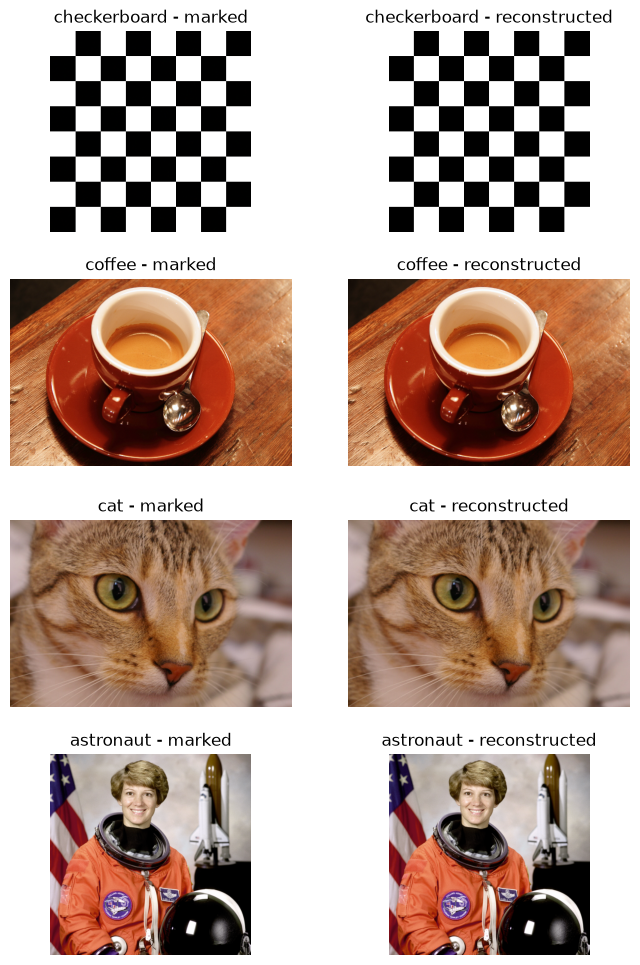

In [6]:
from skimage.metrics import peak_signal_noise_ratio

rng = np.random.default_rng()
figure, axes = plt.subplots(len(imgs_color), 2, figsize=(8, 12))

for row, (image_name, image) in enumerate(zip(image_names, imgs_color)):

    marked_channels = []
    restored_channels = []
    
    for channel_index, channel_name in enumerate(channel_names):
        channel = image[:, :, channel_index]
        
        histogram = compute_histogram(channel)
        peak_point, minimum_point = find_peak_and_minimum_points(histogram)
        
        capacity = histogram[peak_point]

        # generate random binary payload
        bits = rng.integers(0, 2, size=capacity)

        marked, overhead = embed_channel(channel, bits, peak_point, minimum_point)
        restored, extracted_bits = extract_channel(marked, peak_point, minimum_point, overhead, len(bits))

        marked_channels.append(marked)
        restored_channels.append(restored)

        # check if restored image and information are the same
        lossless = (np.array_equal(extracted_bits, bits) and np.array_equal(restored, channel))

        psnr = peak_signal_noise_ratio(channel, marked)
        print(f"{image_name:13s} {channel_name}: capacity={capacity:6d}, overhead={len(overhead):4d}, PSNR={psnr:.2f} dB, lossless={lossless}")

    axes[row, 0].imshow(np.stack(marked_channels, axis=-1))
    axes[row, 0].set_title(f"{image_name} - marked")
    axes[row, 1].imshow(np.stack(restored_channels, axis=-1))
    axes[row, 1].set_title(f"{image_name} - reconstructed")

for axis in axes.ravel():
    axis.axis("off")

plt.show()